# Анализ русскоязычных текстов и классификация тональности

В первой части исследую данные и выделяю темы текстов.
Обучение классификатора тональности относится ко второй части задания.

Источник: [MonoHime/ru_sentiment_dataset на Hugging Face](https://huggingface.co/datasets/MonoHime/ru_sentiment_dataset).

## 1. Загрузка данных

Читаю CSV напрямую по интернет-ссылке с помощью `pd.read_csv(url)`.
После чтения сохраняю исходную таблицу в `data/raw/datasets.csv`
с помощью `to_csv`. Использую существующую папку `data/raw`.
Параметр `index=False` позволяет не добавлять новый столбец индекса.
При повторном запуске ячейка снова читает данные из интернета
и перезаписывает локальную копию. Для этого нужен доступ к сети.


In [41]:
import sys

import pandas as pd

print("Используемый Python:", sys.executable)
print("Версия pandas:", pd.__version__)

Используемый Python: c:\Users\makoc\Work\GazML\.venv\Scripts\python.exe
Версия pandas: 3.0.6


In [ ]:
url = "https://huggingface.co/datasets/MonoHime/ru_sentiment_dataset/resolve/main/datasets.csv"
df = pd.read_csv(url)
df.to_csv("data/raw/datasets.csv", index=False)

print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Названия столбцов:", df.columns.tolist())

df.head()

## 2. Первичный анализ данных

В наборе 210 989 записей. Для дальнейшей работы использую:
- text — исходный текст;
- sentiment — метка тональности.

Проверяю типы данных, пропуски, пустые тексты, повторяющиеся
записи и распределение классов.

In [6]:
data = df[["text", "sentiment"]].copy()

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 210989 entries, 0 to 210988
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   text       210989 non-null  str  
 1   sentiment  210989 non-null  int64
dtypes: int64(1), str(1)
memory usage: 3.2 MB


In [7]:
print("Пропуски по столбцам:")
print(data.isna().sum())

empty_texts = data["text"].fillna("").str.strip().eq("")

print("Пустые тексты или тексты из пробелов:", empty_texts.sum())

print("Повторные пары (текст + тональность):", data.duplicated().sum())

print("Повторные тексты независимо от тональности:", data.duplicated(subset=["text"]).sum())

Пропуски по столбцам:
text         0
sentiment    0
dtype: int64
Пустые тексты или тексты из пробелов: 0
Повторные пары (текст + тональность): 6728
Повторные тексты независимо от тональности: 10539


In [ ]:
label_counts = data.groupby("text")["sentiment"].nunique()

conflicts = label_counts[label_counts>1].index


print("Уникальных текстов с разными метками:", len(conflicts))
print("Всего строк с такими текстами:", data["text"].isin(conflicts).sum())

example_texts = conflicts[:3]

examples = (
    data.loc[
        data["text"].isin(example_texts),
        ["text", "sentiment"]
    ]
    .drop_duplicates()
    .sort_values(["text", "sentiment"])
)

with pd.option_context("display.max_colwidth", 250):
    display(examples)

### Пропуски и повторения

Не обнаружил пропусков в `text` и `sentiment`, пустых текстов и текстов
из пробельных символов.

Обнаружил 6 728 повторных записей по паре «текст + тональность»
и 10 539 повторных записей по тексту независимо от тональности.
Это количество повторов после первого появления, а не всех строк в группах.

Обнаружил разные метки у 3 664 уникальных текстов; они занимают 9 439 строк.
Для общей рабочей таблицы исключаю все такие строки и удаляю оставшиеся
точные повторы. Выбрать достоверную метку без дополнительной проверки нельзя.
Метки нужны для последующей классификации; NMF обучается только по текстам.


In [ ]:
conflict_mask = data["text"].isin(conflicts)
data_clean = data.loc[~conflict_mask].copy()

rows_count = len(data_clean)

data_clean = data_clean.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Исходное количество строк:", len(data))
print("Исключено строк с противоречиями:", conflict_mask.sum())
print("Удалено оставшихся повторов:", rows_count - len(data_clean))
print("Осталось строк:", len(data_clean))

print("Повторные тексты после очистки:", data_clean.duplicated(subset=["text"]).sum())

print("Пропуски после очистки:")
print(data_clean.isna().sum())

In [ ]:
label_names = {
    0: "Нейтральная",
    1: "Положительная",
    2: "Отрицательная"
}

class_counts = data_clean["sentiment"].value_counts().reindex(label_names.keys(), fill_value=0)

names = []
for label in class_counts.index:
    names.append(label_names[label])

class_summary = pd.DataFrame({
    "Тональность": names,
    "Количество": class_counts.to_numpy(),
    "Доля, %": (class_counts / len(data_clean) * 100).round(2).to_numpy()
})

class_summary

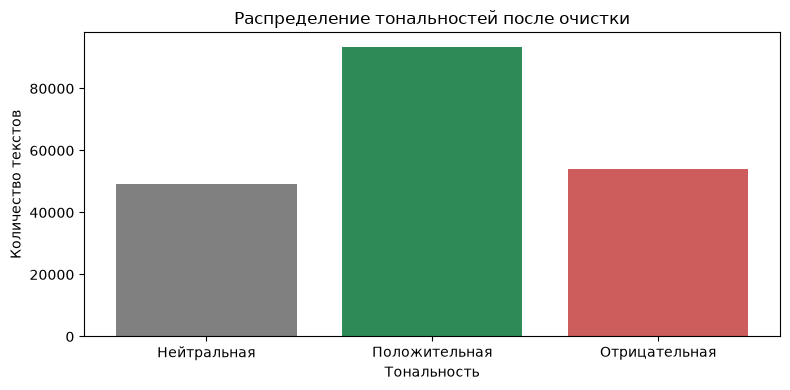

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    class_summary["Тональность"],
    class_summary["Количество"],
    color=["gray", "seagreen", "indianred"]
)

ax.set_title("Распределение тональностей после очистки")
ax.set_xlabel("Тональность")
ax.set_ylabel("Количество текстов")

plt.tight_layout()
plt.show()

In [ ]:
text_lengths = data_clean["text"].str.len()
text_lengths.describe(percentiles=[0.5, 0.6, 0.9, 0.95, 0.99]).round(1)


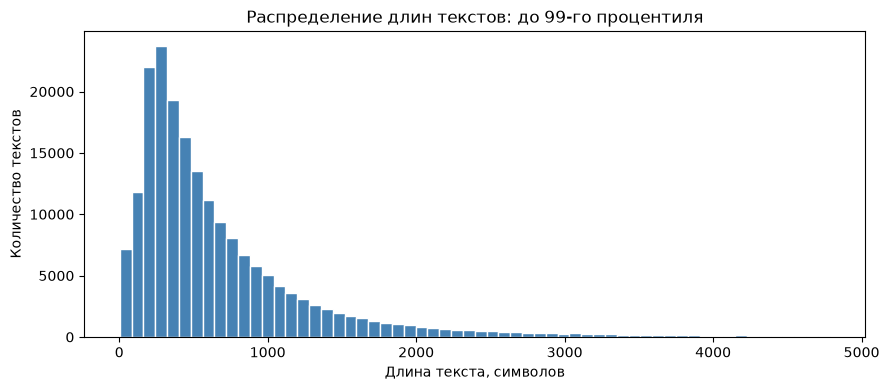

In [17]:
length_limit = text_lengths.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(text_lengths[text_lengths <= length_limit], bins=60, color="steelblue", edgecolor="white")
ax.set_title("Распределение длин текстов: до 99-го процентиля")
ax.set_xlabel("Длина текста, символов")
ax.set_ylabel("Количество текстов")
plt.tight_layout()
plt.show()

### Выводы первичного анализа

1. Исходный набор содержит 210 989 записей. Пропусков и пустых текстов нет.
2. Исключил 9 439 строк с противоречивыми метками и 4 764 оставшихся
   точных повтора. В очищенной таблице — 196 786 текстов.
3. После очистки: нейтральных текстов 25,03%, положительных 47,48%,
   отрицательных 27,49%. При классификации буду учитывать результаты каждого класса.
4. Медианная длина — 471 символ, средняя — около 775 символов.
   99% текстов не длиннее 4 786 символов, максимум — 381 498 символов.
   Для читаемости ограничиваю гистограмму 99-м процентилем;
   длинные тексты из данных не удаляю.
5. Набор неоднороден: встречаются отзывы и информационные материалы.
6. Проверил точные совпадения; поиск близких вариантов текстов
   остаётся возможным улучшением.

Исключение противоречивых записей уменьшает набор и может изменить
распределение классов и тем.


## 3. Тематическое моделирование

Выбрал подход **TF-IDF + NMF**. TF-IDF преобразует тексты в веса слов,
а NMF выделяет компоненты, интерпретируемые по словам и характерным документам.
Причины выбора: работа на CPU, доступность в scikit-learn и понятная интерпретация.

Альтернативы: LDA моделирует документы как смеси тем и обычно использует
количества слов; BERTopic использует нейросетевые представления и кластеризацию.
Выбираю более простой вычислительный процесс без эмбеддингов.
Это обоснование выбора, а не доказательство превосходства NMF по качеству.

Использую **все 196 786 строк очищенной таблицы**.
Вызов `sample` с размером, равным длине таблицы, лишь перемешивает строки;
`random_state=42` фиксирует этот порядок.

Настройки TF-IDF: начальный список русских стоп-слов, `min_df=5`,
`max_df=0.7`, не более 20 000 признаков и `sublinear_tf=True`.
Они ограничивают редкие и слишком распространённые слова, размер словаря
и влияние многократных повторений. Стоп-слова применяются только при поиске тем.

Обучаю **NMF-модель с 10 темами**: `init="nndsvda"`,
`random_state=42`, `max_iter=300`. Число тем задаю как начальную настройку;
систематический подбор не проводил. Метод не учитывает порядок слов;
разные формы слова и синонимы могут учитываться отдельно.


In [ ]:
text_count = len(data_clean)
topic_data = data_clean.sample(n=text_count, random_state=42)

print("Текстов для тематического моделирования:", text_count)

In [33]:
from time import perf_counter

from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

stop_words = [
    "и", "в", "во", "на", "с", "со", "к", "ко", "у", "о", "об", "от", "до",
    "из", "за", "по", "для", "при", "без", "через",
    "а", "но", "или", "да", "же", "бы", "ли", "не", "ни",
    "это", "этот", "эта", "эти", "то", "тот", "та", "те",
    "я", "мы", "ты", "вы", "он", "она", "оно", "они",
    "мне", "меня", "нам", "нас", "вам", "вас", "его", "ее", "их",
    "мой", "моя", "мои", "наш", "наша", "наши",
    "ваш", "ваша", "ваши", "свой", "свои",
    "как", "так", "что", "чтобы", "если", "когда", "где", "куда",
    "уже", "еще", "очень", "был", "была", "было", "были",
    "быть", "есть", "будет", "будут"
]

In [34]:
vectorizer = TfidfVectorizer(stop_words=stop_words, min_df=5, max_df=0.7, max_features=20000, sublinear_tf=True)

started = perf_counter()
tfidf_matrix = vectorizer.fit_transform(topic_data["text"])

print("Размер таблицы TF-IDF:", tfidf_matrix.shape)
print("Время преобразования, секунд:", round(perf_counter() - started, 1))

Размер таблицы TF-IDF: (196786, 20000)
Время преобразования, секунд: 14.1


In [ ]:
n_topics = 10

nmf_model = NMF(n_components=n_topics, init="nndsvda", random_state=42, max_iter=300)

started = perf_counter()
text_topics = nmf_model.fit_transform(tfidf_matrix)

print("Размер таблицы «тексты × темы»:", text_topics.shape)
print("Время обучения, секунд:", round(perf_counter() - started, 1))
print("Количество выполненных итераций:", nmf_model.n_iter_)

In [ ]:
words = vectorizer.get_feature_names_out()

for topic_id, weights in enumerate(nmf_model.components_):
    indices = weights.argsort()[-12:][::-1]
    top_words = words[indices]
    print(f"Тема {topic_id + 1}: {', '.join(top_words)}")

In [ ]:
for topic_id in range(n_topics):
    positions = text_topics[:, topic_id].argsort()[-2:][::-1]
    print(f"\n=== Тема {topic_id + 1} ===")
    

    for position in positions:
        text = topic_data.iloc[position]["text"]
        weight = text_topics[position, topic_id]
        print("Вес темы:", round(weight, 3))
        print(text[:800])
        print()

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for topic_id, ax in enumerate(axes.flat):
    weights = nmf_model.components_[topic_id]
    indices = weights.argsort()[-10:]
    ax.barh(words[indices], weights[indices], color="steelblue")
    ax.set_title(f"Тема {topic_id + 1}")
    ax.set_xlabel("Вес слова в теме")

plt.tight_layout()
plt.show()

### Результаты тематического моделирования

На всех 196 786 очищенных текстах обучил модель TF-IDF + NMF
с 10 темами. TF-IDF-матрица имеет размер 196 786 × 20 000,
а таблица весов тем для документов — 196 786 × 10.

По характерным словам и примерам текстов предлагаю следующую интерпретацию:

| Тема | Интерпретация |
|---|---|
| 1 | Общая разговорная лексика; чёткая предметная тема не выделена |
| 2 | Отели: сервис, персонал и общая оценка |
| 3 | Благодарности медицинским сотрудникам |
| 4 | Рестораны, еда и обслуживание |
| 5 | Казахстан: новости, экономика и государственные инициативы |
| 6 | Медицинские приёмы, врачи и клиники |
| 7 | Общие выражения благодарности |
| 8 | Автомобили и опыт эксплуатации |
| 9 | Номера и условия проживания в отелях |
| 10 | Расположение и транспортная доступность |

Для каждой темы просмотрел два текста с наибольшими весами.
Графики показывают десять характерных слов и их веса внутри каждой темы.
Веса NMF не являются вероятностями. Названия предложил по ручному анализу;
они не выдаются алгоритмом автоматически.

Ограничения: отельная тематика представлена несколькими пересекающимися
аспектами, а некоторые компоненты отражают стиль высказывания.
Разговорная компонента слабо интерпретируется как предметная тема.
Формальные метрики качества и устойчивость результата не проверял.

### Возможные улучшения (без реализации)

1. Предлагаю выполнить лемматизацию: объединить формы «врач», «врача», «врачей».
2. Предлагаю сравнить несколько значений количества тем и параметров TF-IDF.
3. Предлагаю проверить сочетания из двух слов для более точного описания тем.
4. Предлагаю уточнить стоп-слова по результатам анализа, проверяя влияние на темы.
5. Предлагаю проверить устойчивость на разных инициализациях и подвыборках;
   дополнить ручной анализ оценкой связности и разнообразия тем.
6. Предлагаю сравнить с BERTopic на подходящих для русского языка эмбеддингах.
